In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import h5py
from ipywidgets import HBox, VBox

No windowing system present. Using surfaceless platform
No config found!
No config found!


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
✅ (default) | Tesla V100-SXM2-32GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | Tesla V100-SXM2-32GB/PCIe/SSE2 | Unknown | OpenGL | 


In [2]:
movie = tifffile.imread("./data_endoscope.tif")

In [3]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [5]:
movie.shape

(1000, 128, 128)

In [167]:
u, s, v = svds(movie.reshape(1000, movie.shape[1] * movie.shape[2]).T.astype(np.float64))

In [168]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [6]:
_iw_regular_svd = fpl.ImageWidget([ui.reshape(movie.shape[1], movie.shape[2]) for ui in u.T], names=[str(i) for i in range(s.size)], cmap="gnuplot2")
_iw_regular_svd.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

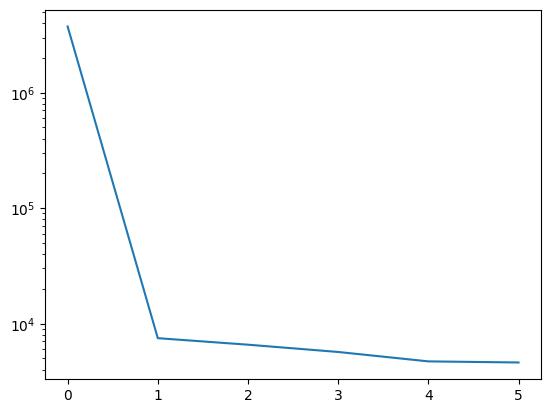

In [7]:
plt.plot(s)
plt.yscale("log")

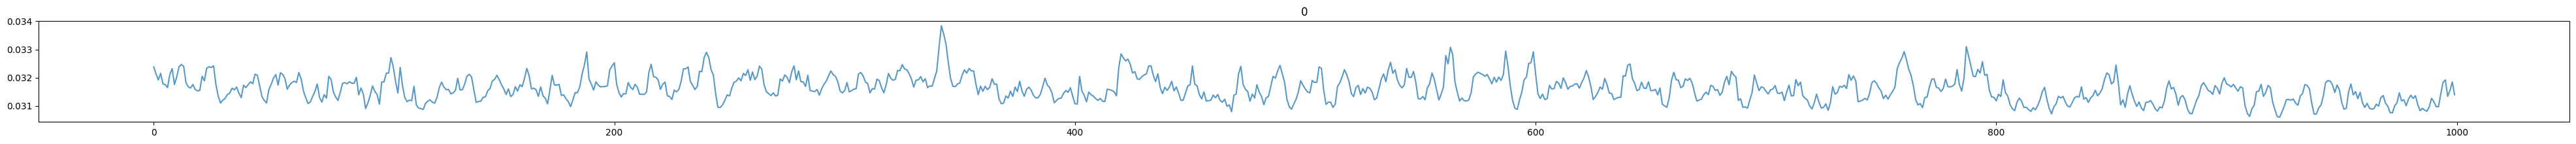

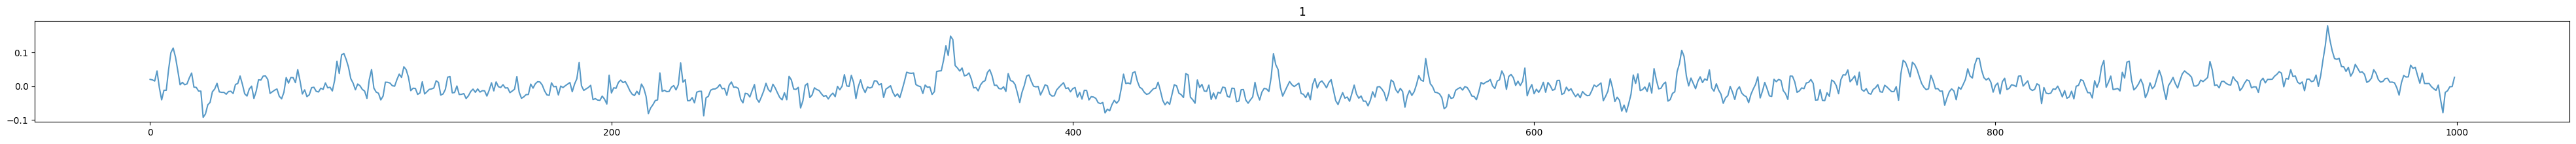

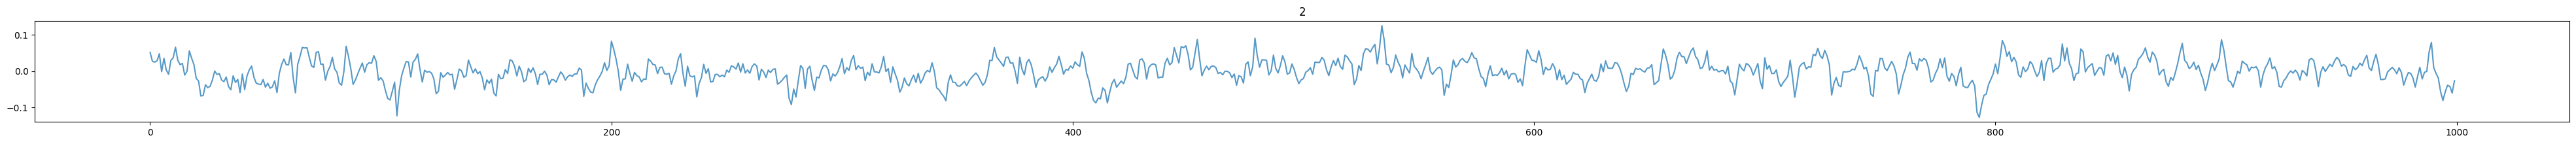

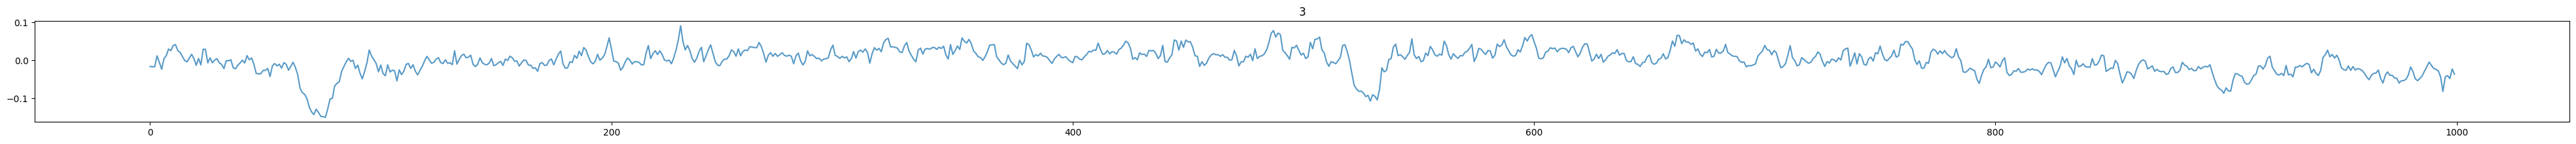

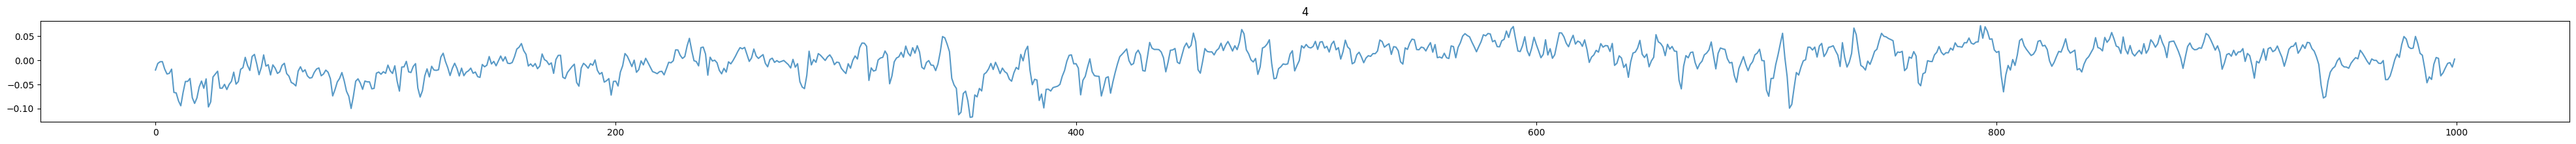

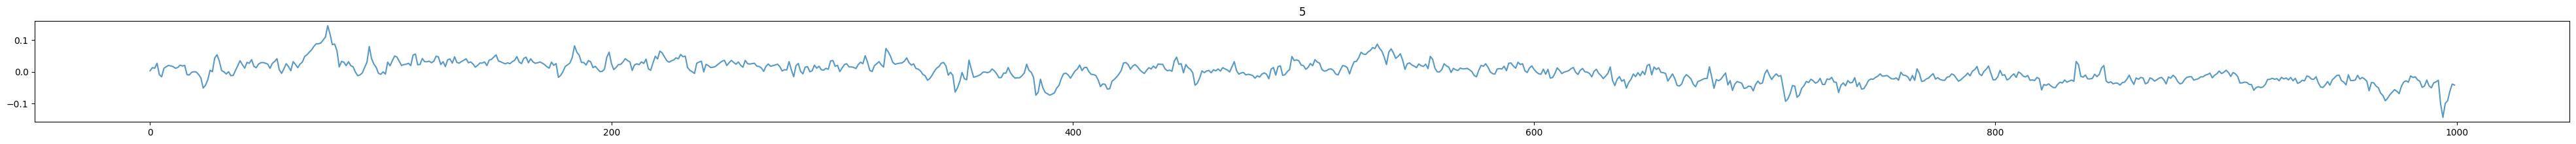

In [8]:
for i, vi in enumerate(v):
    fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    plt.title(i)
    plt.show()
    # if i == 1:
    #     break

In [182]:
sd = np.diag(s)
sd[1:] = 0
recon = (u @ sd @ v).reshape(128, 128, 1000).T.swapaxes(1, 2)

In [183]:
iw_sub = fpl.ImageWidget([movie, recon, movie - recon], names=["movie", "recon", "movie - recon"], cmap="gnuplot2")
iw_sub.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

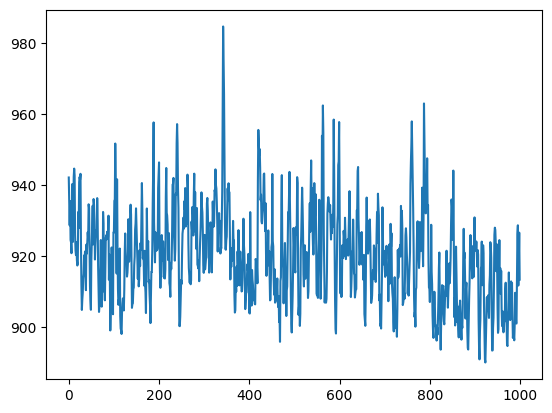

In [185]:
plt.plot(recon.mean(axis=(1, 2)))

In [137]:
substract(movie[0])

ValueError: matmul: Input operand 1 does not have enough dimensions (has 0, gufunc core with signature (n?,k),(k,m?)->(n?,m?) requires 1)

In [118]:
iw_sub.frame_apply = {1: substract}

In [64]:
iw_sub.frame_apply = None